# Session 15: Regression Techniques for Machine Learning

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in []:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-15_simple_linear.py`

In [2]:
"""
Session 15 · Example 1: simple linear regression - by hand and with scikit-learn
--------------------------------------------------------------------------------
Model:  y = b0 + b1 * x   (a straight line)
Least squares chooses b0 and b1 that make the sum of squared errors smallest:
    b1 = sum((x - x_mean)(y - y_mean)) / sum((x - x_mean)^2),   b0 = y_mean - b1 * x_mean
Run:  python session-15_simple_linear.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Monthly advertising spend (Rs thousand) and sales (Rs thousand) for a small shop
ads = np.array([20, 35, 15, 50, 40, 25, 60, 30, 45, 55, 10, 65])
sales = np.array([310, 420, 270, 560, 470, 360, 640, 400, 510, 600, 240, 670])

# 1. By hand
x_mean, y_mean = ads.mean(), sales.mean()
b1 = ((ads - x_mean) * (sales - y_mean)).sum() / ((ads - x_mean) ** 2).sum()
b0 = y_mean - b1 * x_mean
print(f"by hand:      sales = {b0:.2f} + {b1:.3f} x ads")

# 2. With scikit-learn (X must be 2-D: rows = samples, columns = features)
model = LinearRegression().fit(ads.reshape(-1, 1), sales)
print(f"scikit-learn: sales = {model.intercept_:.2f} + {model.coef_[0]:.3f} x ads")
print(f"meaning: every extra Rs 1,000 of advertising is associated with Rs {b1 * 1000:,.0f} more sales")

# 3. Predictions and residuals (errors)
pred = model.predict(ads.reshape(-1, 1))
residuals = sales - pred
for a, s, p, r in list(zip(ads, sales, pred, residuals))[:4]:
    print(f"  ads {a:>2}k: actual {s}, predicted {p:6.1f}, residual {r:+6.1f}")

# 4. Evaluation metrics
mae = mean_absolute_error(sales, pred)
mse = mean_squared_error(sales, pred)
rmse = np.sqrt(mse)
r2 = r2_score(sales, pred)
print(f"\nMAE  = {mae:.2f}   (average absolute error, Rs thousand)")
print(f"MSE  = {mse:.2f}  (average squared error)")
print(f"RMSE = {rmse:.2f}   (typical error, same units as sales)")
print(f"R^2  = {r2:.4f} (share of the variation in sales explained by ads)")
print(f"check R^2 by hand: 1 - SSE/SST = {1 - (residuals ** 2).sum() / ((sales - y_mean) ** 2).sum():.4f}")

# 5. Predict for a new budget - and a warning about extrapolation
for budget in [42, 150]:
    print(f"forecast at {budget}k ads: Rs {model.predict([[budget]])[0]:.0f}k"
          + ("  <- far outside the data (10-65k): do not trust this" if budget > ads.max() * 1.5 else ""))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
xs = np.linspace(0, 70, 2)
ax[0].scatter(ads, sales, color="#A78BFA", zorder=3, label="months")
ax[0].plot(xs, model.predict(xs.reshape(-1, 1)), color="#FF6B1A", lw=2, label=f"fit: R² = {r2:.3f}")
for a, s, p in zip(ads, sales, pred):
    ax[0].plot([a, a], [s, p], color="gray", lw=0.8)
ax[0].set(xlabel="ad spend (Rs k)", ylabel="sales (Rs k)", title="Least-squares line; grey = residuals"); ax[0].legend()
ax[1].scatter(pred, residuals, color="#F43F5E"); ax[1].axhline(0, color="black", lw=1)
ax[1].set(xlabel="predicted sales", ylabel="residual", title="Residuals: no pattern = good fit")
fig.tight_layout(); fig.savefig("session-15_simple_linear.png", dpi=100)
print("Saved session-15_simple_linear.png")

by hand:      sales = 153.38 + 8.021 x ads
scikit-learn: sales = 153.38 + 8.021 x ads
meaning: every extra Rs 1,000 of advertising is associated with Rs 8,021 more sales
  ads 20k: actual 310, predicted  313.8, residual   -3.8
  ads 35k: actual 420, predicted  434.1, residual  -14.1
  ads 15k: actual 270, predicted  273.7, residual   -3.7
  ads 50k: actual 560, predicted  554.4, residual   +5.6

MAE  = 5.82   (average absolute error, Rs thousand)
MSE  = 40.84  (average squared error)
RMSE = 6.39   (typical error, same units as sales)
R^2  = 0.9979 (share of the variation in sales explained by ads)
check R^2 by hand: 1 - SSE/SST = 0.9979
forecast at 42k ads: Rs 490k
forecast at 150k ads: Rs 1357k  <- far outside the data (10-65k): do not trust this
Saved session-15_simple_linear.png


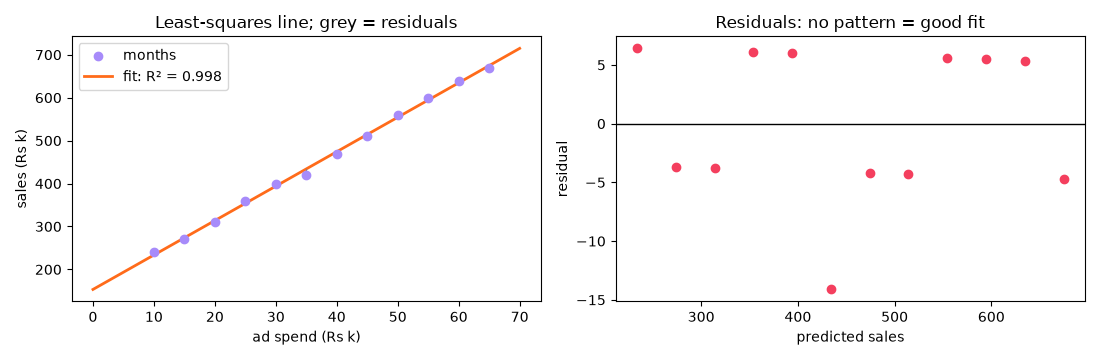

In [3]:
from IPython.display import Image, display
display(Image(filename='session-15_simple_linear.png'))  # chart saved by the cell above

## Example: `session-15_multiple_polynomial.py`

In [4]:
"""
Session 15 · Example 2: multiple and polynomial regression, and overfitting
---------------------------------------------------------------------------
Multiple regression:   y = b0 + b1*x1 + b2*x2 + ...      (several features)
Polynomial regression: y = b0 + b1*x + b2*x^2 + ...      (a curve, still 'linear' in the b's)
Too high a degree memorises noise: low training error, high test error.
Run:  python session-15_multiple_polynomial.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

rng = np.random.default_rng(15)
# ---- Part A: multiple linear regression - monthly electricity use of homes ----
n = 300
homes = pd.DataFrame({"area_sqyd": rng.integers(80, 500, n), "people": rng.integers(1, 9, n),
                      "acs": rng.integers(0, 4, n), "avg_temp": rng.uniform(18, 38, n).round(1)})
homes["units"] = (50 + 0.6 * homes.area_sqyd + 25 * homes.people + 140 * homes.acs * (homes.avg_temp - 15) / 10
                  + rng.normal(0, 40, n)).round(0)
X, y = homes.drop(columns="units"), homes["units"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0)
lin = LinearRegression().fit(Xtr, ytr)
print("Multiple regression: units =", f"{lin.intercept_:.1f}",
      " ".join(f"{c:+.2f}*{f}" for f, c in zip(X.columns, lin.coef_)))
print(f"test R^2 = {r2_score(yte, lin.predict(Xte)):.3f}, RMSE = {np.sqrt(mean_squared_error(yte, lin.predict(Xte))):.1f} units")
std = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
print("standardised coefficients (comparable importance):",
      {f: round(float(c), 1) for f, c in zip(X.columns, std[-1].coef_)})

# An interaction feature captures 'ACs matter more on hot days'
homes["ac_heat"] = homes.acs * homes.avg_temp
Xtr2, Xte2 = Xtr.join(homes.loc[Xtr.index, ["ac_heat"]]), Xte.join(homes.loc[Xte.index, ["ac_heat"]])
lin2 = LinearRegression().fit(Xtr2, ytr)
print(f"with interaction feature ac_heat: test R^2 = {r2_score(yte, lin2.predict(Xte2)):.3f}")

# ---- Part B: polynomial regression and overfitting ----
x = np.sort(rng.uniform(0, 10, 40))
y_curve = 2 + 1.5 * x - 0.12 * x ** 2 + rng.normal(0, 0.6, 40)     # a gentle curve + noise
xtr, xte, ytr_c, yte_c = train_test_split(x.reshape(-1, 1), y_curve, test_size=0.3, random_state=2)
print("\ndegree  train RMSE  test RMSE")
results = {}
for d in [1, 2, 3, 6, 12]:
    m = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression()).fit(xtr, ytr_c)
    tr = np.sqrt(mean_squared_error(ytr_c, m.predict(xtr)))
    te = np.sqrt(mean_squared_error(yte_c, m.predict(xte)))
    results[d] = (m, tr, te)
    print(f"{d:>6}  {tr:10.3f}  {te:9.3f}" + ("   <- underfits" if d == 1 else "   <- overfits" if d == 12 else ""))
best = min(results, key=lambda d: results[d][2])
print("best degree on the test set:", best)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
grid = np.linspace(0, 10, 300).reshape(-1, 1)
ax[0].scatter(xtr, ytr_c, color="#6B7280", s=18, label="train"); ax[0].scatter(xte, yte_c, color="#F43F5E", s=18, label="test")
for d, col in [(1, "#A78BFA"), (2, "#FF6B1A"), (12, "#22C55E")]:
    ax[0].plot(grid, np.clip(results[d][0].predict(grid), -5, 15), color=col, label=f"degree {d}")
ax[0].set_ylim(-1, 9); ax[0].legend(fontsize=8); ax[0].set_title("Underfit, good fit, overfit")
ds = list(results)
ax[1].plot(ds, [results[d][1] for d in ds], "o-", color="#FF6B1A", label="train RMSE")
ax[1].plot(ds, [results[d][2] for d in ds], "s-", color="#F43F5E", label="test RMSE")
ax[1].set_yscale("log"); ax[1].set_xlabel("polynomial degree"); ax[1].legend(); ax[1].set_title("Training error keeps falling; test error does not")
fig.tight_layout(); fig.savefig("session-15_multiple_polynomial.png", dpi=100)
print("Saved session-15_multiple_polynomial.png")

Multiple regression: units = -525.4 +0.53*area_sqyd +20.73*people +176.79*acs +21.86*avg_temp
test R^2 = 0.848, RMSE = 101.4 units
standardised coefficients (comparable importance): {'area_sqyd': 63.9, 'people': 45.2, 'acs': 201.5, 'avg_temp': 127.9}
with interaction feature ac_heat: test R^2 = 0.979

degree  train RMSE  test RMSE
     1       0.960      1.256   <- underfits
     2       0.543      0.767
     3       0.543      0.745
     6       0.474      0.878
    12       0.454      1.172   <- overfits
best degree on the test set: 3


Saved session-15_multiple_polynomial.png


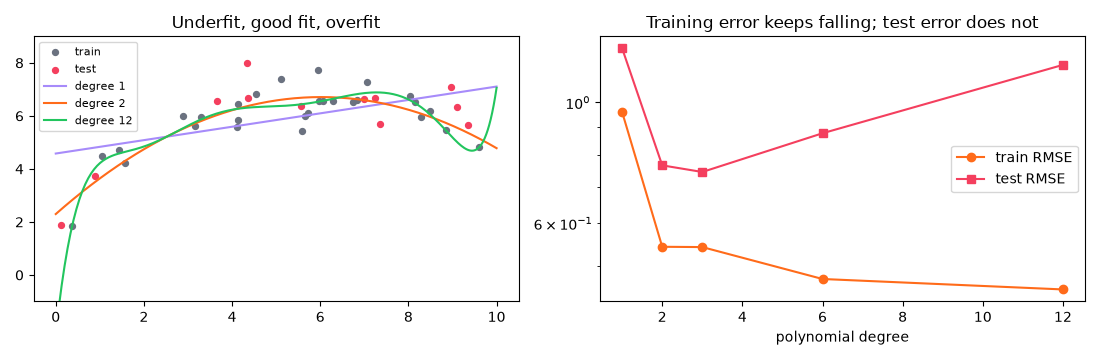

In [5]:
from IPython.display import Image, display
display(Image(filename='session-15_multiple_polynomial.png'))  # chart saved by the cell above

## Example: `session-15_regularization_and_trees.py`

In [6]:
"""
Session 15 · Example 3: regularised and non-linear regression techniques
------------------------------------------------------------------------
Compare, with 5-fold cross-validation on the SAME data:
  LinearRegression | Ridge (L2 penalty) | Lasso (L1 penalty, can zero out features)
  DecisionTreeRegressor | RandomForestRegressor | KNeighborsRegressor | SVR
The data has 10 features but only 4 truly matter, plus a non-linear effect.
Run:  python session-15_regularization_and_trees.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(150)
n, p = 250, 10
X = pd.DataFrame(rng.normal(0, 1, (n, p)), columns=[f"x{i}" for i in range(1, p + 1)])
y = 3 * X.x1 - 2 * X.x2 + 1.5 * X.x3 + 4 * np.sin(1.5 * X.x4) + rng.normal(0, 1, n)   # x5..x10 are noise

cv = KFold(5, shuffle=True, random_state=0)
models = {
    "Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (alpha=10)": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Lasso (alpha=0.1)": make_pipeline(StandardScaler(), Lasso(alpha=0.1)),
    "Decision tree (depth 4)": DecisionTreeRegressor(max_depth=4, random_state=0),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=0),
    "k-NN (k=7)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=7)),
    "SVR (RBF kernel)": make_pipeline(StandardScaler(), SVR(C=10)),
}
scores = {}
print(f"{'model':<25} {'CV R^2':>7} {'CV RMSE':>8}")
for name, m in models.items():
    r2 = cross_val_score(m, X, y, cv=cv, scoring="r2").mean()
    rmse = -cross_val_score(m, X, y, cv=cv, scoring="neg_root_mean_squared_error").mean()
    scores[name] = (r2, rmse)
    print(f"{name:<25} {r2:7.3f} {rmse:8.3f}")

# What did the linear models learn?
coef = pd.DataFrame({name: models[name].fit(X, y)[-1].coef_ for name in ["Linear", "Ridge (alpha=10)", "Lasso (alpha=0.1)"]},
                    index=X.columns).round(2)
print("\nCoefficients (features standardised):\n", coef.T.to_string())
print("Lasso set", int((coef["Lasso (alpha=0.1)"] == 0).sum()), "noise features exactly to zero")

rf = models["Random forest"].fit(X, y)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nRandom-forest feature importances:", imp.head(5).round(3).to_dict())

# Ridge: how alpha shrinks coefficients
alphas = np.logspace(-2, 4, 30)
paths = np.array([make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X, y)[-1].coef_ for a in alphas])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
names = list(scores)
ax[0].barh(names, [scores[k][0] for k in names], color=["#A78BFA"] * 3 + ["#FCD34D"] * 2 + ["#FF6B1A"] * 2)
ax[0].set_xlabel("cross-validated R²"); ax[0].set_title("Same data, different techniques"); ax[0].invert_yaxis()
for i, col in enumerate(X.columns):
    ax[1].plot(alphas, paths[:, i], color="#FF6B1A" if i < 4 else "#BBBBBB", lw=2 if i < 4 else 1)
ax[1].set_xscale("log"); ax[1].set_xlabel("Ridge alpha (penalty strength)"); ax[1].set_ylabel("coefficient")
ax[1].set_title("Ridge shrinks all coefficients toward 0 (orange = real features)")
fig.tight_layout(); fig.savefig("session-15_regularization_and_trees.png", dpi=95)
print("Saved session-15_regularization_and_trees.png")

model                      CV R^2  CV RMSE
Linear                      0.747    2.378


Ridge (alpha=10)            0.748    2.383
Lasso (alpha=0.1)           0.758    2.335
Decision tree (depth 4)     0.478    3.468


Random forest               0.780    2.279
k-NN (k=7)                  0.588    3.112
SVR (RBF kernel)            0.772    2.294

Coefficients (features standardised):
                      x1    x2    x3    x4    x5    x6    x7    x8    x9   x10
Linear             2.91 -2.36  1.06  1.63  0.11 -0.01 -0.01 -0.02  0.15  0.02
Ridge (alpha=10)   2.80 -2.28  1.04  1.57  0.12 -0.00 -0.01 -0.02  0.15  0.01
Lasso (alpha=0.1)  2.83 -2.28  0.98  1.53  0.01 -0.00 -0.00 -0.00  0.05 -0.00
Lasso set 4 noise features exactly to zero



Random-forest feature importances: {'x1': 0.393, 'x4': 0.237, 'x2': 0.237, 'x3': 0.049, 'x8': 0.016}


Saved session-15_regularization_and_trees.png


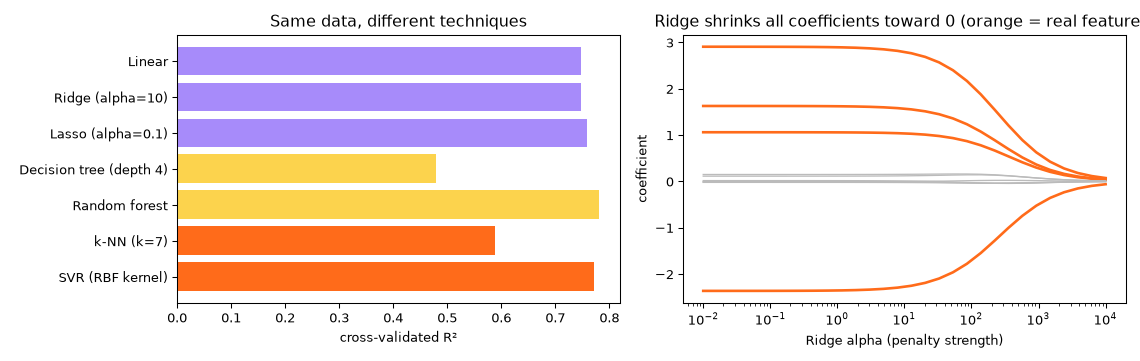

In [7]:
from IPython.display import Image, display
display(Image(filename='session-15_regularization_and_trees.png'))  # chart saved by the cell above

## Example: `session-15_problem_house_prices.py`

In [8]:
"""
Session 15 · Real-life problem: estimating house prices
-------------------------------------------------------
PROBLEM
A property portal wants an instant price estimate for listings. Using past
sales (synthetic, seeded; prices in million rupees) with area, bedrooms, age,
neighbourhood and corner-plot flag:
  1. explore the target (prices are right-skewed -> model log(price)),
  2. build a preprocessing + model pipeline (one-hot neighbourhoods, scale numbers),
  3. compare linear regression, ridge and random forest with cross-validation,
  4. evaluate the best model on a held-out test set (MAE, RMSE, R^2, % error),
  5. check residuals, explain the linear model, and price three new listings.
Run:  python session-15_problem_house_prices.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

pd.set_option("display.width", 130)
rng = np.random.default_rng(2025)
areas = {"DHA": 1.55, "Clifton": 1.45, "Gulshan": 1.0, "North Nazimabad": 0.85, "Malir": 0.6}
n = 700
df = pd.DataFrame({
    "area_sqyd": rng.choice([120, 200, 240, 300, 400, 500, 1000], n, p=[0.2, 0.22, 0.18, 0.15, 0.12, 0.09, 0.04]),
    "bedrooms": rng.integers(2, 7, n),
    "age_years": rng.integers(0, 35, n),
    "neighbourhood": rng.choice(list(areas), n, p=[0.2, 0.12, 0.28, 0.25, 0.15]),
    "corner": (rng.random(n) < 0.15).astype(int),
})
mult = df["neighbourhood"].map(areas)
df["price_m"] = (0.13 * df.area_sqyd ** 0.95 * mult * (1 - 0.008 * df.age_years) * (1 + 0.06 * df.bedrooms)
                 * (1 + 0.1 * df.corner) * np.exp(rng.normal(0, 0.12, n))).round(1)
print(df.head(), "\n")
print(f"price: median {df.price_m.median():.1f} M, mean {df.price_m.mean():.1f} M, skew {df.price_m.skew():.2f} "
      f"(log price skew {np.log(df.price_m).skew():.2f})")

X, y = df.drop(columns="price_m"), df["price_m"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=7)
num, cat = ["area_sqyd", "bedrooms", "age_years", "corner"], ["neighbourhood"]
prep = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])

# An interpretable design for the linear model: log(area) because price grows with area in
# percentage terms, other numbers kept in their own units, and Gulshan as the reference area.
prep_lin = ColumnTransformer([("logarea", FunctionTransformer(np.log, feature_names_out="one-to-one"), ["area_sqyd"]),
                              ("num", "passthrough", ["bedrooms", "age_years", "corner"]),
                              ("cat", OneHotEncoder(drop=["Gulshan"], handle_unknown="ignore"), cat)])

def log_model(reg, pre=prep):
    """Fit on log(price), predict back in million rupees."""
    return TransformedTargetRegressor(regressor=Pipeline([("prep", pre), ("reg", reg)]), func=np.log, inverse_func=np.exp)

candidates = {"Linear (log price)": log_model(LinearRegression()),
              "Ridge (log price)": log_model(Ridge(alpha=1.0)),
              "Linear + log(area)": log_model(LinearRegression(), prep_lin),
              "Random forest": Pipeline([("prep", prep), ("reg", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0))])}
print("\n5-fold CV on the training set:")
cv_mae = {}
for name, m in candidates.items():
    cv_mae[name] = -cross_val_score(m, X_tr, y_tr, cv=5, scoring="neg_mean_absolute_error").mean()
    print(f"  {name:<20} MAE {cv_mae[name]:.2f} M")
best_name = min(cv_mae, key=cv_mae.get)
best = candidates[best_name].fit(X_tr, y_tr)
pred = best.predict(X_te)
print(f"\nbest: {best_name}. Test set: MAE {mean_absolute_error(y_te, pred):.2f} M | "
      f"RMSE {np.sqrt(mean_squared_error(y_te, pred)):.2f} M | R^2 {r2_score(y_te, pred):.3f} | "
      f"median % error {np.median(np.abs(pred - y_te) / y_te) * 100:.1f}%")

lin = candidates["Linear + log(area)"].fit(X_tr, y_tr)
names = lin.regressor_.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lin.regressor_.named_steps["reg"].coef_, index=names)
print("\nInterpretable model (log price ~ log area + ...): what each feature does to the price")
print(f"  area                   +1 % area -> +{coefs['logarea__area_sqyd']:.2f} % price (elasticity)")
for f, unit in [("num__bedrooms", "per extra bedroom"), ("num__age_years", "per year of age"), ("num__corner", "corner plot"),
                ("cat__neighbourhood_DHA", "DHA vs Gulshan"), ("cat__neighbourhood_Clifton", "Clifton vs Gulshan"),
                ("cat__neighbourhood_Malir", "Malir vs Gulshan")]:
    print(f"  {unit:<22} x{np.exp(coefs[f]):.3f}")

new = pd.DataFrame({"area_sqyd": [240, 500, 120], "bedrooms": [3, 5, 2], "age_years": [5, 12, 25],
                    "neighbourhood": ["Gulshan", "DHA", "Malir"], "corner": [0, 1, 0]})
new["estimate_m"] = best.predict(new).round(1)
print("\nEstimates for new listings:\n", new.to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.7))
ax[0].hist(df.price_m, bins=40, color="#FF6B1A"); ax[0].set_title("Prices are right-skewed"); ax[0].set_xlabel("price (M Rs)")
ax[1].scatter(y_te, pred, s=12, color="#A78BFA"); lim = [0, max(y_te.max(), pred.max()) * 1.05]
ax[1].plot(lim, lim, color="black", lw=1); ax[1].set(xlim=lim, ylim=lim, xlabel="actual", ylabel="predicted",
                                                    title=f"{best_name}: predicted vs actual")
ax[2].scatter(pred, (y_te - pred) / y_te * 100, s=12, color="#F43F5E"); ax[2].axhline(0, color="black", lw=1)
ax[2].set(xlabel="predicted price", ylabel="error (% of actual)", title="Residuals in % (no funnel = good)")
fig.tight_layout(); fig.savefig("session-15_problem_house_prices.png", dpi=95)
print("Saved session-15_problem_house_prices.png")

   area_sqyd  bedrooms  age_years neighbourhood  corner  price_m
0       1000         3         10         Malir       0     54.3
1        200         5         24           DHA       0     38.3
2        400         5          1         Malir       0     35.7
3        400         2          2       Clifton       1     65.6
4       1000         3         33           DHA       0    132.8 

price: median 26.1 M, mean 33.2 M, skew 2.72 (log price skew 0.34)

5-fold CV on the training set:
  Linear (log price)   MAE 6.70 M
  Ridge (log price)    MAE 6.68 M
  Linear + log(area)   MAE 3.12 M


  Random forest        MAE 3.86 M

best: Linear + log(area). Test set: MAE 2.66 M | RMSE 3.82 M | R^2 0.965 | median % error 7.9%

Interpretable model (log price ~ log area + ...): what each feature does to the price
  area                   +1 % area -> +0.93 % price (elasticity)
  per extra bedroom      x1.046
  per year of age        x0.991
  corner plot            x1.101
  DHA vs Gulshan         x1.563
  Clifton vs Gulshan     x1.479
  Malir vs Gulshan       x0.593

Estimates for new listings:
  area_sqyd  bedrooms  age_years neighbourhood  corner  estimate_m
       240         3          5       Gulshan       0        26.9
       500         5         12           DHA       1        94.5
       120         2         25         Malir       0         6.7


Saved session-15_problem_house_prices.png


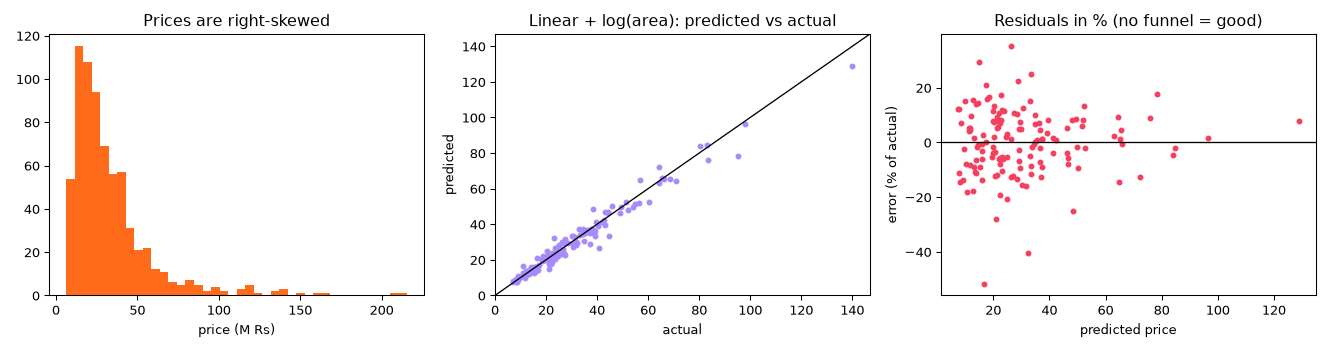

In [9]:
from IPython.display import Image, display
display(Image(filename='session-15_problem_house_prices.png'))  # chart saved by the cell above

## Example: `session-15_project_delivery_eta.py`

In [10]:
"""
Session 15 · Mini project: a food-delivery arrival-time (ETA) estimator
-----------------------------------------------------------------------
A delivery app must tell customers "your order arrives in N minutes".
We build a regression model end to end:
  1. synthetic order history: distance, kitchen prep time, hour, rain, rider rating, weekend
  2. feature engineering: rush-hour flag (lunch 12-14, dinner 19-22)
  3. compare a baseline (average time), linear regression and gradient boosting
  4. evaluate with MAE and "within 5 minutes" accuracy, plus a prediction interval
     from the residuals so the app can say "25-31 min" instead of a single number
  5. wrap everything in estimate_eta(order) and test it on new orders
Run:  python session-15_project_delivery_eta.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(55)
n = 2000
orders = pd.DataFrame({
    "distance_km": rng.gamma(2.2, 1.8, n).round(1),
    "prep_min": rng.integers(8, 30, n),
    "hour": rng.choice(range(11, 24), n),
    "rain": (rng.random(n) < 0.12).astype(int),
    "rider_rating": np.clip(rng.normal(4.5, 0.3, n), 3, 5).round(1),
    "weekend": (rng.random(n) < 2 / 7).astype(int),
})
orders["rush"] = orders["hour"].isin([12, 13, 19, 20, 21]).astype(int)
travel = orders.distance_km * (3.2 + 2.0 * orders.rush + 2.5 * orders.rain) * (1.1 - 0.05 * (orders.rider_rating - 4.5))
orders["minutes"] = (orders.prep_min + travel + 3 + 2 * orders.weekend + rng.normal(0, 3, n)).clip(lower=10).round(0)
features = ["distance_km", "prep_min", "rush", "rain", "rider_rating", "weekend"]
print(orders.head(), f"\n\n{n} past orders, average delivery {orders.minutes.mean():.1f} min")

X_tr, X_te, y_tr, y_te = train_test_split(orders[features], orders["minutes"], test_size=0.25, random_state=3)
results = {}
baseline = np.full(len(y_te), y_tr.mean())
results["Baseline (always the average)"] = baseline
lin = LinearRegression().fit(X_tr, y_tr)
results["Linear regression"] = lin.predict(X_te)
gbr = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=0).fit(X_tr, y_tr)
results["Gradient boosting"] = gbr.predict(X_te)

print(f"\n{'model':<30} {'MAE (min)':>9} {'within 5 min':>13}")
for name, pred in results.items():
    print(f"{name:<30} {mean_absolute_error(y_te, pred):>9.2f} {np.mean(np.abs(pred - y_te) <= 5):>12.0%}")

print("\nLinear model: minutes =", f"{lin.intercept_:.1f}", " ".join(f"{c:+.2f}*{f}" for f, c in zip(features, lin.coef_)))
print("  (one model for everyone: it cannot express that rain and rush hour slow down EACH km)")
imp = pd.Series(gbr.feature_importances_, index=features).sort_values(ascending=False)
print("Gradient boosting feature importances:", imp.round(3).to_dict())

# A simple prediction interval: the 10th and 90th percentiles of the test residuals
resid = y_te - results["Gradient boosting"]
lo, hi = np.percentile(resid, [10, 90])
coverage = np.mean((resid >= lo) & (resid <= hi))
print(f"\n80 % interval from residuals: prediction {lo:+.1f} to {hi:+.1f} min (covers {coverage:.0%} of test orders)")

def estimate_eta(order):
    """Return (low, best, high) minutes for one order dict, rounded for the app screen."""
    row = pd.DataFrame([order])
    row["rush"] = int(order["hour"] in (12, 13, 19, 20, 21))
    best = float(gbr.predict(row[features])[0])
    return round(best + lo), round(best), round(best + hi)

print("\nNew orders:")
for o in [dict(distance_km=1.5, prep_min=12, hour=16, rain=0, rider_rating=4.8, weekend=0),
          dict(distance_km=6.0, prep_min=20, hour=20, rain=0, rider_rating=4.4, weekend=1),
          dict(distance_km=6.0, prep_min=20, hour=20, rain=1, rider_rating=4.4, weekend=1)]:
    low, best, high = estimate_eta(o)
    print(f"  {o['distance_km']} km, prep {o['prep_min']} min, {o['hour']}:00, rain={o['rain']} -> "
          f"'Arriving in {low}-{high} min' (best guess {best})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(y_te, results["Gradient boosting"], s=8, alpha=0.5, color="#FF6B1A", label="gradient boosting")
ax[0].scatter(y_te, results["Linear regression"], s=8, alpha=0.3, color="#A78BFA", label="linear")
m = [y_te.min(), y_te.max()]; ax[0].plot(m, m, color="black", lw=1)
ax[0].set(xlabel="actual minutes", ylabel="predicted minutes", title="Predicted vs actual"); ax[0].legend(fontsize=8)
ax[1].barh(imp.index[::-1], imp.values[::-1], color="#F43F5E"); ax[1].set_title("What drives delivery time?")
fig.tight_layout(); fig.savefig("session-15_project_delivery_eta.png", dpi=100)
print("Saved session-15_project_delivery_eta.png")

   distance_km  prep_min  hour  rain  rider_rating  weekend  rush  minutes
0          5.9        15    17     0           4.9        0     0     37.0
1          2.7        21    17     0           4.6        0     0     40.0
2          1.1        23    11     0           4.8        1     0     34.0
3          8.6        15    13     0           4.5        0     1     68.0
4          5.8        23    14     0           4.3        0     0     48.0 

2000 past orders, average delivery 40.2 min



model                          MAE (min)  within 5 min
Baseline (always the average)      10.98          25%
Linear regression                   3.48          76%
Gradient boosting                   2.55          90%

Linear model: minutes = 1.5 +4.64*distance_km +1.03*prep_min +8.86*rush +10.97*rain -0.81*rider_rating +1.97*weekend
  (one model for everyone: it cannot express that rain and rush hour slow down EACH km)
Gradient boosting feature importances: {'distance_km': 0.673, 'prep_min': 0.169, 'rush': 0.089, 'rain': 0.064, 'weekend': 0.003, 'rider_rating': 0.002}

80 % interval from residuals: prediction -4.0 to +4.2 min (covers 80% of test orders)

New orders:
  1.5 km, prep 12 min, 16:00, rain=0 -> 'Arriving in 15-23 min' (best guess 19)
  6.0 km, prep 20 min, 20:00, rain=0 -> 'Arriving in 55-63 min' (best guess 59)
  6.0 km, prep 20 min, 20:00, rain=1 -> 'Arriving in 67-75 min' (best guess 71)
Saved session-15_project_delivery_eta.png


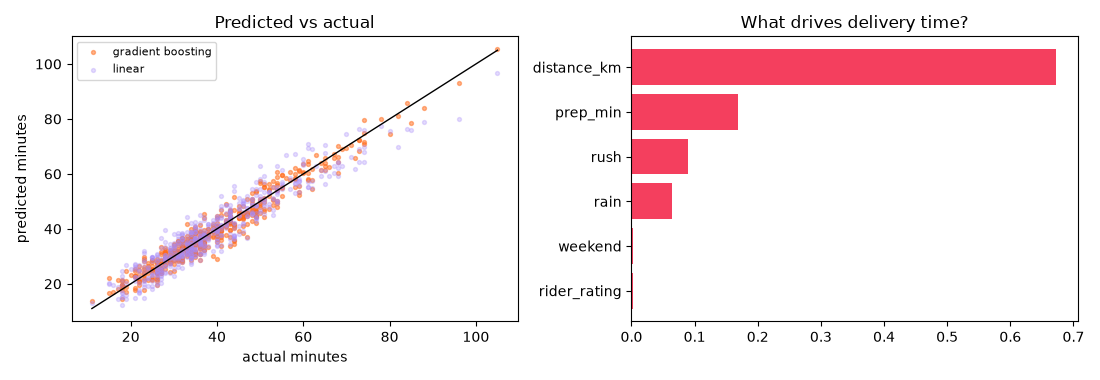

In [11]:
from IPython.display import Image, display
display(Image(filename='session-15_project_delivery_eta.png'))  # chart saved by the cell above